## Problem 8: Predicting Energy Industry Excess Returns Using Fama-French Factors

**Importing Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

**Load Fama-French 5-Factor data**

In [2]:
ff5_url = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_5_Factors_2x3_CSV.zip"

ff5_raw = pd.read_csv(
    ff5_url,
    compression="zip",
    skiprows=3
)

ff5_raw.head()

,Unnamed: 0,Mkt-RF,SMB,HML,RMW,CMA,RF
0,196307,-0.39,-0.48,-0.81,0.64,-1.15,0.27
1,196308,5.08,-0.80,1.70,0.40,-0.38,0.25
2,196309,-1.57,-0.43,0.00,-0.78,0.15,0.27
3,196310,2.54,-1.34,-0.04,2.79,-2.25,0.29
4,196311,-0.86,-0.85,1.73,-0.43,2.27,0.27


**Clean Fama-French 5-Factor data**

In [3]:
ff5 = ff5_raw.copy()

ff5 = ff5.rename(columns={ff5.columns[0]: "Date"})

ff5 = ff5[ff5["Date"].astype(str).str.isnumeric()]
ff5 = ff5[ff5["Date"].astype(str).str.len() == 6]

ff5["Date"] = pd.to_datetime(ff5["Date"].astype(str), format="%Y%m")

ff5["Mkt-RF"] = pd.to_numeric(ff5["Mkt-RF"], errors="coerce")
ff5["SMB"] = pd.to_numeric(ff5["SMB"], errors="coerce")
ff5["HML"] = pd.to_numeric(ff5["HML"], errors="coerce")
ff5["RMW"] = pd.to_numeric(ff5["RMW"], errors="coerce")
ff5["CMA"] = pd.to_numeric(ff5["CMA"], errors="coerce")
ff5["RF"] = pd.to_numeric(ff5["RF"], errors="coerce")

ff5.head()

,Date,Mkt-RF,SMB,HML,RMW,CMA,RF
0,1963-07-01,-0.39,-0.48,-0.81,0.64,-1.15,0.27
1,1963-08-01,5.08,-0.80,1.70,0.40,-0.38,0.25
2,1963-09-01,-1.57,-0.43,0.00,-0.78,0.15,0.27
3,1963-10-01,2.54,-1.34,-0.04,2.79,-2.25,0.29
4,1963-11-01,-0.86,-0.85,1.73,-0.43,2.27,0.27


**Load 10 Industry Portfolios data**

In [4]:
industry_url = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/10_Industry_Portfolios_CSV.zip"

industry_raw = pd.read_csv(
    industry_url,
    compression="zip",
    skiprows=11
)

industry_raw.head()

,Unnamed: 0,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
0,192607,1.44,13.90,4.70,-1.14,2.90,0.83,0.12,1.85,7.04,2.14
1,192608,3.99,3.70,2.80,3.43,2.66,2.17,-0.72,4.17,-1.70,4.35
2,192609,1.15,4.98,1.17,-3.30,-0.39,2.42,0.21,0.69,2.05,0.31
3,192610,-1.24,-8.39,-3.65,-0.78,-4.58,-0.11,-2.29,-0.57,-3.27,-2.85
4,192611,5.21,-0.17,4.27,0.01,4.71,1.63,6.45,5.43,4.40,2.13


**Keep only the first monthly returns table**

In [5]:
industry = industry_raw.copy()

industry = industry.rename(columns={industry.columns[0]: "Date"})

industry["Date_as_text"] = industry["Date"].astype(str)

first_non_monthly_row = industry[
    ~industry["Date_as_text"].str.isnumeric()
].index[0]

industry = industry.loc[:first_non_monthly_row - 1]

industry.head()

,Date,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other,Date_as_text
0,192607,1.44,13.90,4.70,-1.14,2.90,0.83,0.12,1.85,7.04,2.14,192607
1,192608,3.99,3.70,2.80,3.43,2.66,2.17,-0.72,4.17,-1.70,4.35,192608
2,192609,1.15,4.98,1.17,-3.30,-0.39,2.42,0.21,0.69,2.05,0.31,192609
3,192610,-1.24,-8.39,-3.65,-0.78,-4.58,-0.11,-2.29,-0.57,-3.27,-2.85,192610
4,192611,5.21,-0.17,4.27,0.01,4.71,1.63,6.45,5.43,4.40,2.13,192611


**Clean Energy industry returns**

In [6]:
industry = industry.drop(columns=["Date_as_text"])

industry["Date"] = pd.to_datetime(industry["Date"].astype(str), format="%Y%m")

industry["Enrgy"] = pd.to_numeric(industry["Enrgy"], errors="coerce")

industry[["Date", "Enrgy"]].head()

,Date,Enrgy
0,1926-07-01,-1.14
1,1926-08-01,3.43
2,1926-09-01,-3.30
3,1926-10-01,-0.78
4,1926-11-01,0.01


**Merge factor data and industry data**

In [7]:
data = pd.merge(
    ff5,
    industry[["Date", "Enrgy"]],
    on="Date",
    how="inner"
)

data.head()

,Date,Mkt-RF,SMB,HML,RMW,CMA,RF,Enrgy
0,1963-07-01,-0.39,-0.48,-0.81,0.64,-1.15,0.27,2.30
1,1963-08-01,5.08,-0.80,1.70,0.40,-0.38,0.25,3.94
2,1963-09-01,-1.57,-0.43,0.00,-0.78,0.15,0.27,-3.65
3,1963-10-01,2.54,-1.34,-0.04,2.79,-2.25,0.29,-0.33
4,1963-11-01,-0.86,-0.85,1.73,-0.43,2.27,0.27,-1.14


In [8]:
data.shape

(755, 8)

**Create Energy excess return**

In [9]:
data["Enrgy_Excess"] = data["Enrgy"] - data["RF"]

data[
    [
        "Date",
        "Enrgy",
        "RF",
        "Enrgy_Excess",
        "Mkt-RF",
        "SMB",
        "HML",
        "RMW",
        "CMA"
    ]
].head()

,Date,Enrgy,RF,Enrgy_Excess,Mkt-RF,SMB,HML,RMW,CMA
0,1963-07-01,2.30,0.27,2.03,-0.39,-0.48,-0.81,0.64,-1.15
1,1963-08-01,3.94,0.25,3.69,5.08,-0.80,1.70,0.40,-0.38
2,1963-09-01,-3.65,0.27,-3.92,-1.57,-0.43,0.00,-0.78,0.15
3,1963-10-01,-0.33,0.29,-0.62,2.54,-1.34,-0.04,2.79,-2.25
4,1963-11-01,-1.14,0.27,-1.41,-0.86,-0.85,1.73,-0.43,2.27


**Create train and test data**

In [10]:
train = data[data["Date"] < "2000-01-01"].copy()
test = data[data["Date"] >= "2000-01-01"].copy()

train.shape, test.shape

((438, 9), (317, 9))

**Define X and y**

In [11]:
factors = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]

X_train = train[factors]
y_train = train["Enrgy_Excess"]

X_test = test[factors]
y_test = test["Enrgy_Excess"]

**Fit OLS**

In [12]:
ols_model = Pipeline([
    ("scaler", StandardScaler()),
    ("linear", LinearRegression())
])

ols_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('linear', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Mkt-RF','SMB','HML','RMW','CMA']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


**Fit Ridge Regression**

In [13]:
alpha_values = np.logspace(-4, 4, 50)

time_split = TimeSeriesSplit(n_splits=5)

ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", RidgeCV(alphas=alpha_values, cv=time_split))
])

ridge_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Mkt-RF','SMB','HML','RMW','CMA']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


**Check selected Ridge alpha**

In [14]:
best_alpha = ridge_model.named_steps["ridge"].alpha_

best_alpha

np.float64(3.727593720314938)

**Make Predictions**

In [15]:
ols_predictions = ols_model.predict(X_test)

ridge_predictions = ridge_model.predict(X_test)

**Compare Model Performance**

In [16]:
ols_rmse = np.sqrt(mean_squared_error(y_test, ols_predictions))
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))

ols_mae = mean_absolute_error(y_test, ols_predictions)
ridge_mae = mean_absolute_error(y_test, ridge_predictions)

ols_r2 = r2_score(y_test, ols_predictions)
ridge_r2 = r2_score(y_test, ridge_predictions)

performance_comparison = pd.DataFrame({
    "Model": ["OLS Linear Regression", "Ridge Regression"],
    "RMSE": [ols_rmse, ridge_rmse],
    "MAE": [ols_mae, ridge_mae],
    "Test R-squared": [ols_r2, ridge_r2]
})

performance_comparison

,Model,RMSE,MAE,Test R-squared
0,OLS Linear Regression,5.951606,4.363695,0.296767
1,Ridge Regression,5.953637,4.367643,0.296287


**Compare Coefficients**

In [17]:
ols_coefficients = ols_model.named_steps["linear"].coef_

ridge_coefficients = ridge_model.named_steps["ridge"].coef_

coefficient_comparison = pd.DataFrame({
    "Factor": factors,
    "OLS Coefficient": ols_coefficients,
    "Ridge Coefficient": ridge_coefficients
})

coefficient_comparison["Absolute OLS Coefficient"] = coefficient_comparison["OLS Coefficient"].abs()
coefficient_comparison["Absolute Ridge Coefficient"] = coefficient_comparison["Ridge Coefficient"].abs()

coefficient_comparison

,Factor,OLS Coefficient,Ridge Coefficient,Absolute OLS Coefficient,Absolute Ridge Coefficient
0,Mkt-RF,4.135009,4.082238,4.135009,4.082238
1,SMB,-0.660600,-0.648264,0.660600,0.648264
2,HML,-0.290746,-0.277574,0.290746,0.277574
3,RMW,-0.300387,-0.305841,0.300387,0.305841
4,CMA,1.067171,1.024706,1.067171,1.024706


**Plot: OLS vs Ridge coefficients**

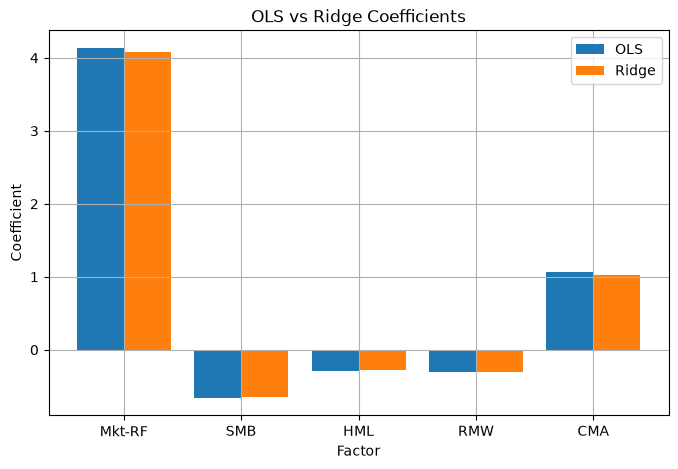

In [18]:
plt.figure(figsize=(8, 5))

x = np.arange(len(factors))

plt.bar(x - 0.2, coefficient_comparison["OLS Coefficient"], width=0.4, label="OLS")
plt.bar(x + 0.2, coefficient_comparison["Ridge Coefficient"], width=0.4, label="Ridge")

plt.xticks(x, factors)

plt.xlabel("Factor")
plt.ylabel("Coefficient")
plt.title("OLS vs Ridge Coefficients")
plt.legend()
plt.grid(True)

plt.show()

**Plot: Actual vs Predicted Energy Excess Returns**

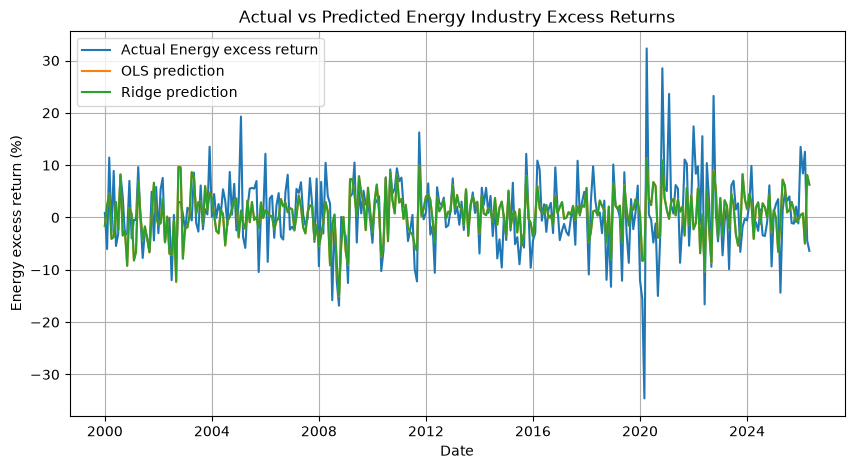

In [19]:
prediction_plot = test[["Date", "Enrgy_Excess"]].copy()

prediction_plot["OLS_Prediction"] = ols_predictions
prediction_plot["Ridge_Prediction"] = ridge_predictions

plt.figure(figsize=(10, 5))

plt.plot(
    prediction_plot["Date"],
    prediction_plot["Enrgy_Excess"],
    label="Actual Energy excess return"
)

plt.plot(
    prediction_plot["Date"],
    prediction_plot["OLS_Prediction"],
    label="OLS prediction"
)

plt.plot(
    prediction_plot["Date"],
    prediction_plot["Ridge_Prediction"],
    label="Ridge prediction"
)

plt.xlabel("Date")
plt.ylabel("Energy excess return (%)")
plt.title("Actual vs Predicted Energy Industry Excess Returns")
plt.legend()
plt.grid(True)

plt.show()

**Residual comparison**

In [20]:
prediction_plot["OLS_Residual"] = (
    prediction_plot["Enrgy_Excess"] - prediction_plot["OLS_Prediction"]
)

prediction_plot["Ridge_Residual"] = (
    prediction_plot["Enrgy_Excess"] - prediction_plot["Ridge_Prediction"]
)

residual_comparison = pd.DataFrame({
    "Model": ["OLS Linear Regression", "Ridge Regression"],
    "Residual Mean": [
        prediction_plot["OLS_Residual"].mean(),
        prediction_plot["Ridge_Residual"].mean()
    ],
    "Residual Standard Deviation": [
        prediction_plot["OLS_Residual"].std(),
        prediction_plot["Ridge_Residual"].std()
    ]
})

residual_comparison

,Model,Residual Mean,Residual Standard Deviation
0,OLS Linear Regression,0.206087,5.957441
1,Ridge Regression,0.207153,5.959439


## END